Saving plasma_G1_1min_FINAL.csv to plasma_G1_1min_FINAL.csv

CONTINUOUS SEGMENTS
            N                     Start                       End  Duration_h
segment                                                                      
13       7664 2026-08-28 21:13:00+00:00 2026-09-03 04:56:00+00:00  127.716667
15       7218 2026-09-03 04:58:01+00:00 2026-09-08 05:15:00+00:00  120.283056
12       3449 2026-08-26 11:43:01+00:00 2026-08-28 21:11:00+00:00   57.466389
8        2993 2026-08-23 05:12:01+00:00 2026-08-25 07:04:00+00:00   49.866389
7        2044 2026-08-21 19:07:00+00:00 2026-08-23 05:10:00+00:00   34.050000
10       1716 2026-08-25 07:06:00+00:00 2026-08-26 11:41:01+00:00   28.583611
17        592 2026-09-08 05:17:00+00:00 2026-09-08 15:08:00+00:00    9.850000
18        362 2026-09-08 15:10:16+00:00 2026-09-08 21:11:01+00:00    6.012500
20         28 2026-09-08 21:13:01+00:00 2026-09-08 21:40:00+00:00    0.449722
3           1 2026-08-21 18:40:01+00:00 2026-08-21 18:40:01+0

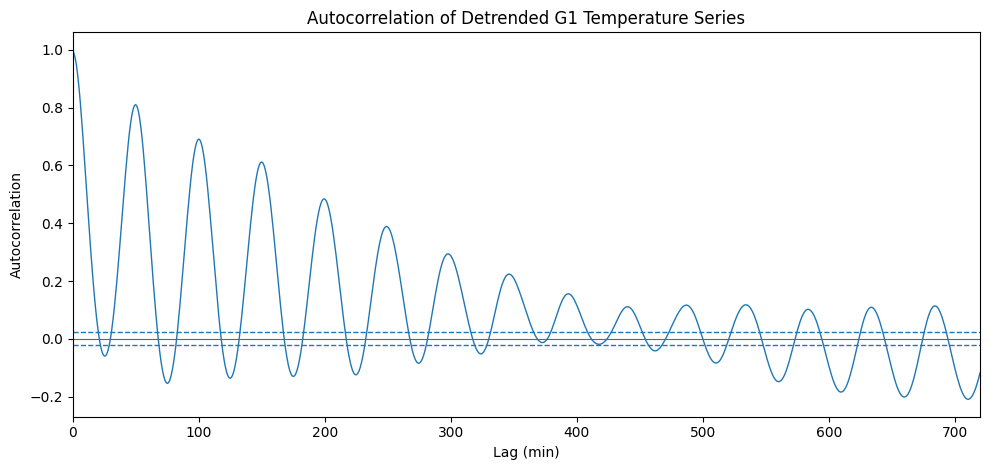

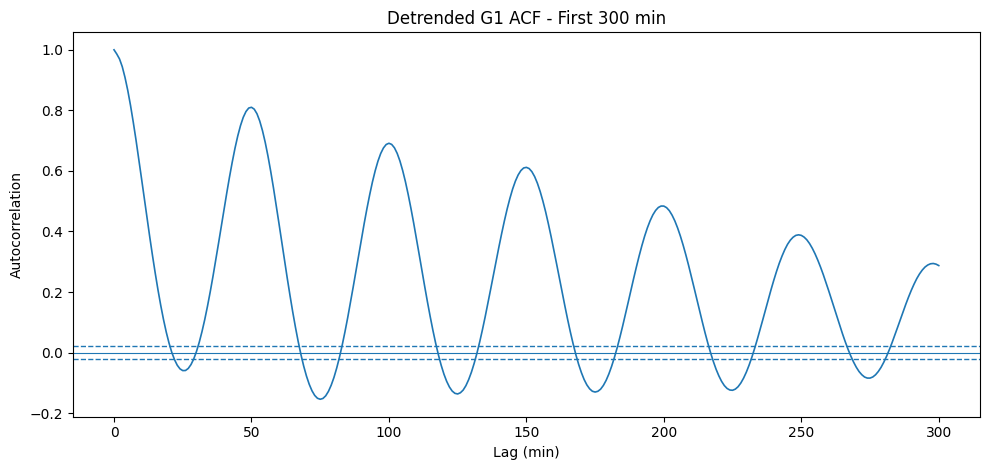


TRUE SUBSAMPLING RESULTS
 Sampling_interval_min     N  Data_reduction_pct     Mean_C  Median_C     SD_C  Min_C  Max_C
                     1 26077            0.000000 -30.581328     -30.5 0.679628  -32.1  -28.2
                     2 13045           49.975074 -30.581365     -30.5 0.679547  -32.1  -28.2
                     3  8703           66.625762 -30.581535     -30.5 0.679312  -32.1  -28.2
                     5  5228           79.951682 -30.581503     -30.5 0.678837  -32.1  -28.2
                    10  2622           89.945162 -30.582113     -30.5 0.677414  -32.1  -28.2

LINEAR RECONSTRUCTION ERROR
 Sampling_interval_min  N_evaluated    MAE_C   RMSE_C  P95_absolute_error_C  Maximum_absolute_error_C
                     2        26059 0.015066 0.029345              0.050413                  0.250000
                     3        26058 0.022808 0.035417              0.066851                  0.400000
                     5        26049 0.029760 0.041505              0.080066      

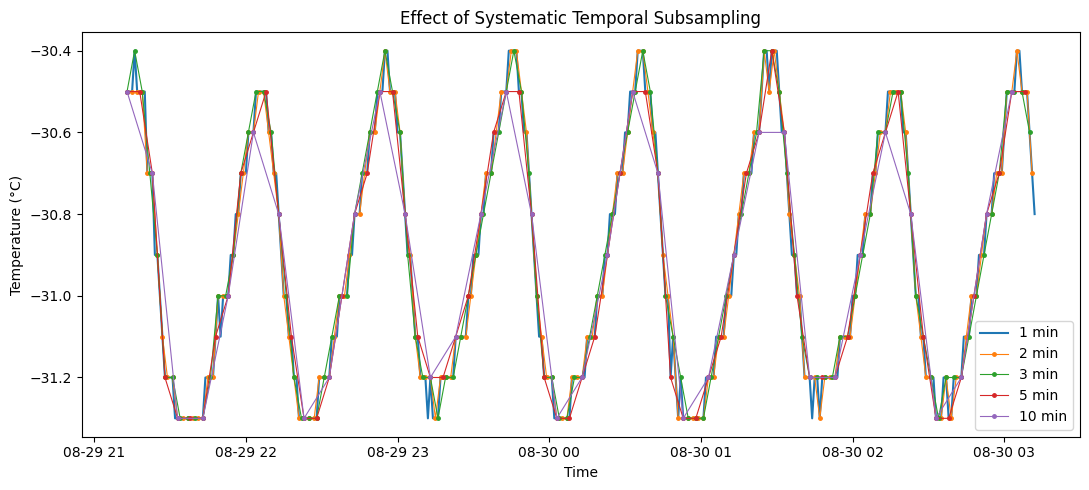

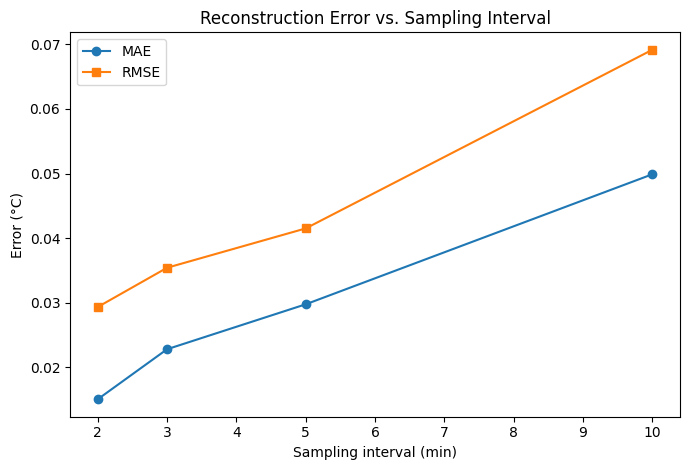

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (9 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


G1 PART 2 COMPLETED
Reduced-resolution series were generated by systematic point selection, NOT temporal aggregation.
Reconstruction used linear interpolation without extrapolation and without bridging acquisition gaps.


In [1]:
# ============================================================
# PAPER 02 - HRFEST 2026
# G1 ANALYSIS - PART 2
#
# 1. Continuous-segment identification
# 2. Linear detrending
# 3. ACF with 95% confidence limits
# 4. Recurrent-pattern detection
# 5. True systematic temporal subsampling
# 6. Linear reconstruction
# 7. MAE / RMSE / Maximum absolute error
# 8. Data-reduction assessment
#
# IMPORTANT:
# Reduced-resolution series are created by POINT SELECTION,
# NOT by median/mean temporal aggregation.
# ============================================================

!pip -q install statsmodels

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from scipy.signal import detrend, find_peaks
from statsmodels.tsa.stattools import acf


# ============================================================
# 1. UPLOAD G1
# ============================================================

uploaded = files.upload()

filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

datetime_col = "datetime"
temperature_col = "dsTemperature"

df[datetime_col] = pd.to_datetime(
    df[datetime_col],
    errors="coerce",
    utc=True
)

df[temperature_col] = pd.to_numeric(
    df[temperature_col],
    errors="coerce"
)

df = (
    df
    .dropna(subset=[datetime_col, temperature_col])
    .sort_values(datetime_col)
    .drop_duplicates(subset=[datetime_col])
    .reset_index(drop=True)
)


# ============================================================
# 2. CALCULATE TIME INTERVALS
# ============================================================

df["interval_min"] = (
    df[datetime_col]
    .diff()
    .dt.total_seconds()
    / 60
)


# ============================================================
# 3. IDENTIFY CONTINUOUS ~1-MIN SEGMENTS
# ============================================================
#
# A new segment begins whenever the interval is:
# < 0.5 min OR > 1.5 min
#
# This avoids bridging real acquisition gaps.
# ============================================================

break_mask = (
    df["interval_min"].isna()
    |
    (df["interval_min"] < 0.5)
    |
    (df["interval_min"] > 1.5)
)

df["segment"] = break_mask.cumsum()

segment_summary = (
    df.groupby("segment")
    .agg(
        N=(temperature_col, "size"),
        Start=(datetime_col, "min"),
        End=(datetime_col, "max")
    )
)

segment_summary["Duration_h"] = (
    (
        segment_summary["End"]
        - segment_summary["Start"]
    )
    .dt.total_seconds()
    / 3600
)

segment_summary = (
    segment_summary
    .sort_values("N", ascending=False)
)


print("\n====================================================")
print("CONTINUOUS SEGMENTS")
print("====================================================")

print(segment_summary.head(15))


largest_segment_id = segment_summary.index[0]

continuous = (
    df[
        df["segment"] == largest_segment_id
    ]
    .copy()
    .reset_index(drop=True)
)


print("\nLongest segment:")
print("N =", len(continuous))
print("Start =", continuous[datetime_col].min())
print("End =", continuous[datetime_col].max())


# ============================================================
# 4. LINEAR DETRENDING
# ============================================================

series = (
    continuous[temperature_col]
    .astype(float)
    .values
)

detrended = detrend(
    series,
    type="linear"
)

continuous["temperature_detrended"] = detrended


# ============================================================
# 5. AUTOCORRELATION FUNCTION
# ============================================================
#
# Up to 12 hours:
# 720 lags x approximately 1 min
# ============================================================

MAX_LAG = 720

acf_values = acf(
    detrended,
    nlags=MAX_LAG,
    fft=True
)


# Approximate 95% confidence threshold
confidence_95 = (
    1.96 / np.sqrt(len(detrended))
)


print("\n====================================================")
print("ACF ANALYSIS")
print("====================================================")

print("N used:", len(detrended))
print("Maximum lag:", MAX_LAG, "min")

print(
    "Approximate 95% confidence threshold:",
    round(confidence_95, 6)
)


# ============================================================
# 6. FIND POSITIVE ACF PEAKS
# ============================================================
#
# Ignore the very short-lag region.
# Search from lag >= 10 min.
# ============================================================

search_acf = acf_values.copy()

search_acf[:10] = 0


peaks, properties = find_peaks(
    search_acf,
    height=confidence_95,
    distance=20,
    prominence=0.05
)


peak_table = pd.DataFrame({
    "Lag_min": peaks,
    "ACF": acf_values[peaks]
})


peak_table = (
    peak_table
    .sort_values(
        "Lag_min"
    )
    .reset_index(drop=True)
)


print("\n====================================================")
print("SIGNIFICANT POSITIVE ACF PEAKS")
print("====================================================")

print(
    peak_table
    .head(30)
    .to_string(index=False)
)


# ============================================================
# 7. STRONGEST RECURRENT PEAKS
# ============================================================

strongest_peaks = (
    peak_table
    .sort_values(
        "ACF",
        ascending=False
    )
    .head(15)
)


print("\n====================================================")
print("STRONGEST ACF PEAKS")
print("====================================================")

print(
    strongest_peaks
    .to_string(index=False)
)


# ============================================================
# 8. ACF FIGURE WITH 95% CONFIDENCE BOUNDS
# ============================================================

lags = np.arange(
    len(acf_values)
)


plt.figure(
    figsize=(10, 4.8)
)

plt.plot(
    lags,
    acf_values,
    linewidth=1.0
)

plt.axhline(
    confidence_95,
    linestyle="--",
    linewidth=1
)

plt.axhline(
    -confidence_95,
    linestyle="--",
    linewidth=1
)

plt.axhline(
    0,
    linewidth=0.8
)

plt.xlabel("Lag (min)")
plt.ylabel("Autocorrelation")
plt.title(
    "Autocorrelation of Detrended G1 Temperature Series"
)

plt.xlim(
    0,
    MAX_LAG
)

plt.tight_layout()

plt.savefig(
    "G1_ACF_detrended.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 9. ACF ZOOM - FIRST 300 MIN
# ============================================================

plt.figure(
    figsize=(10, 4.8)
)

plt.plot(
    lags[:301],
    acf_values[:301],
    linewidth=1.2
)

plt.axhline(
    confidence_95,
    linestyle="--",
    linewidth=1
)

plt.axhline(
    -confidence_95,
    linestyle="--",
    linewidth=1
)

plt.axhline(
    0,
    linewidth=0.8
)

plt.xlabel("Lag (min)")
plt.ylabel("Autocorrelation")

plt.title(
    "Detrended G1 ACF - First 300 min"
)

plt.tight_layout()

plt.savefig(
    "G1_ACF_detrended_300min.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 10. TRUE SYSTEMATIC TEMPORAL SUBSAMPLING
# ============================================================
#
# IMPORTANT:
#
# We DO NOT aggregate observations.
#
# We select every k-th REAL observation from each continuous
# ~1-min segment:
#
# k = 1, 2, 3, 5, 10
#
# Each segment restarts its sampling sequence independently,
# preventing a gap from changing the sampling phase.
# ============================================================

intervals = [
    1,
    2,
    3,
    5,
    10
]


subsampled_sets = {}


for k in intervals:

    pieces = []

    for segment_id, group in df.groupby("segment"):

        group = (
            group
            .sort_values(datetime_col)
            .reset_index(drop=True)
        )

        if k == 1:

            selected = group.copy()

        else:

            selected = (
                group.iloc[::k]
                .copy()
            )

        pieces.append(selected)


    reduced = (
        pd.concat(
            pieces,
            ignore_index=True
        )
        .sort_values(datetime_col)
        .reset_index(drop=True)
    )

    subsampled_sets[k] = reduced


# ============================================================
# 11. DESCRIPTIVE STATISTICS OF SUBSAMPLED SERIES
# ============================================================

sampling_results = []


N_reference = len(
    subsampled_sets[1]
)


for k in intervals:

    reduced = subsampled_sets[k]

    values = reduced[temperature_col]

    reduction_pct = (
        100
        *
        (
            1
            - len(reduced) / N_reference
        )
    )


    sampling_results.append({
        "Sampling_interval_min":
            k,

        "N":
            len(reduced),

        "Data_reduction_pct":
            reduction_pct,

        "Mean_C":
            values.mean(),

        "Median_C":
            values.median(),

        "SD_C":
            values.std(ddof=1),

        "Min_C":
            values.min(),

        "Max_C":
            values.max()
    })


sampling_table = pd.DataFrame(
    sampling_results
)


print("\n====================================================")
print("TRUE SUBSAMPLING RESULTS")
print("====================================================")

print(
    sampling_table
    .to_string(
        index=False
    )
)


# ============================================================
# 12. RECONSTRUCTION ERROR
# ============================================================
#
# For each continuous segment:
#
# 1. select every k-th real observation
# 2. reconstruct temperature at the original timestamps
#    using LINEAR INTERPOLATION
# 3. evaluate only timestamps bounded by sampled observations
#
# No extrapolation is performed.
#
# Real acquisition gaps are NEVER bridged because each
# continuous segment is processed separately.
# ============================================================

error_results = []

reconstruction_examples = {}


for k in [
    2,
    3,
    5,
    10
]:

    all_actual = []
    all_reconstructed = []
    all_times = []


    for segment_id, group in df.groupby("segment"):

        group = (
            group
            .sort_values(datetime_col)
            .reset_index(drop=True)
        )

        # Need at least two sampled observations
        sampled = (
            group.iloc[::k]
            .copy()
        )

        if len(sampled) < 2:
            continue


        # ----------------------------------------------------
        # Convert timestamps to numeric seconds
        # ----------------------------------------------------

        original_x = (
            group[datetime_col]
            .astype("int64")
            .to_numpy()
            / 1e9
        )

        sampled_x = (
            sampled[datetime_col]
            .astype("int64")
            .to_numpy()
            / 1e9
        )

        sampled_y = (
            sampled[temperature_col]
            .astype(float)
            .to_numpy()
        )


        # ----------------------------------------------------
        # No extrapolation
        # ----------------------------------------------------

        valid_mask = (
            (original_x >= sampled_x.min())
            &
            (original_x <= sampled_x.max())
        )


        target_x = original_x[
            valid_mask
        ]


        actual_y = (
            group.loc[
                valid_mask,
                temperature_col
            ]
            .astype(float)
            .to_numpy()
        )


        reconstructed_y = np.interp(
            target_x,
            sampled_x,
            sampled_y
        )


        all_actual.extend(
            actual_y
        )

        all_reconstructed.extend(
            reconstructed_y
        )

        all_times.extend(
            group.loc[
                valid_mask,
                datetime_col
            ]
            .tolist()
        )


    all_actual = np.array(
        all_actual
    )

    all_reconstructed = np.array(
        all_reconstructed
    )


    errors = (
        all_reconstructed
        - all_actual
    )

    abs_errors = np.abs(
        errors
    )


    MAE = np.mean(
        abs_errors
    )

    RMSE = np.sqrt(
        np.mean(
            errors ** 2
        )
    )

    MAX_ERROR = np.max(
        abs_errors
    )

    P95_ERROR = np.percentile(
        abs_errors,
        95
    )


    error_results.append({
        "Sampling_interval_min":
            k,

        "N_evaluated":
            len(all_actual),

        "MAE_C":
            MAE,

        "RMSE_C":
            RMSE,

        "P95_absolute_error_C":
            P95_ERROR,

        "Maximum_absolute_error_C":
            MAX_ERROR
    })


    reconstruction_examples[k] = pd.DataFrame({
        "datetime":
            all_times,

        "actual_temperature_C":
            all_actual,

        "reconstructed_temperature_C":
            all_reconstructed,

        "error_C":
            errors,

        "absolute_error_C":
            abs_errors
    })


error_table = pd.DataFrame(
    error_results
)


print("\n====================================================")
print("LINEAR RECONSTRUCTION ERROR")
print("====================================================")

print(
    error_table
    .to_string(
        index=False
    )
)


# ============================================================
# 13. COMBINED ENGINEERING TABLE
# ============================================================

engineering_table = (
    sampling_table
    .merge(
        error_table,
        on="Sampling_interval_min",
        how="left"
    )
)


print("\n====================================================")
print("ENGINEERING SAMPLING TABLE")
print("====================================================")

print(
    engineering_table
    .to_string(
        index=False
    )
)


# ============================================================
# 14. VISUAL COMPARISON - SELECT ONE 6-HOUR WINDOW
# ============================================================
#
# Choose a window from the longest continuous segment.
# ============================================================

window_start = (
    continuous[datetime_col]
    .iloc[0]
    +
    pd.Timedelta(hours=24)
)

window_end = (
    window_start
    +
    pd.Timedelta(hours=6)
)


plt.figure(
    figsize=(11, 5)
)


reference_window = df[
    (df[datetime_col] >= window_start)
    &
    (df[datetime_col] <= window_end)
]


plt.plot(
    reference_window[datetime_col],
    reference_window[temperature_col],
    linewidth=1.5,
    label="1 min"
)


for k in [
    2,
    3,
    5,
    10
]:

    reduced = subsampled_sets[k]

    reduced_window = reduced[
        (reduced[datetime_col] >= window_start)
        &
        (reduced[datetime_col] <= window_end)
    ]

    plt.plot(
        reduced_window[datetime_col],
        reduced_window[temperature_col],
        marker="o",
        markersize=2.5,
        linewidth=0.8,
        label=f"{k} min"
    )


plt.xlabel("Time")
plt.ylabel("Temperature (°C)")

plt.title(
    "Effect of Systematic Temporal Subsampling"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    "G1_subsampling_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 15. ERROR VS SAMPLING INTERVAL FIGURE
# ============================================================

plt.figure(
    figsize=(7, 4.8)
)

plt.plot(
    error_table["Sampling_interval_min"],
    error_table["MAE_C"],
    marker="o",
    label="MAE"
)

plt.plot(
    error_table["Sampling_interval_min"],
    error_table["RMSE_C"],
    marker="s",
    label="RMSE"
)

plt.xlabel(
    "Sampling interval (min)"
)

plt.ylabel(
    "Error (°C)"
)

plt.title(
    "Reconstruction Error vs. Sampling Interval"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    "G1_error_vs_sampling_interval.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 16. EXPORT TABLES
# ============================================================

segment_summary.to_csv(
    "G1_continuous_segments.csv"
)

peak_table.to_csv(
    "G1_ACF_peaks.csv",
    index=False
)

sampling_table.to_csv(
    "G1_true_subsampling_statistics.csv",
    index=False
)

error_table.to_csv(
    "G1_reconstruction_errors.csv",
    index=False
)

engineering_table.to_csv(
    "G1_engineering_sampling_table.csv",
    index=False
)


# Export reduced datasets
for k in intervals:

    subsampled_sets[k].to_csv(
        f"G1_subsampled_{k}min.csv",
        index=False
    )


# ============================================================
# 17. DOWNLOAD IMPORTANT RESULTS
# ============================================================

files_to_download = [

    "G1_continuous_segments.csv",
    "G1_ACF_peaks.csv",

    "G1_true_subsampling_statistics.csv",
    "G1_reconstruction_errors.csv",
    "G1_engineering_sampling_table.csv",

    "G1_ACF_detrended.png",
    "G1_ACF_detrended_300min.png",

    "G1_subsampling_comparison.png",
    "G1_error_vs_sampling_interval.png"
]


for f in files_to_download:
    files.download(f)


print("\n====================================================")
print("G1 PART 2 COMPLETED")
print("====================================================")

print(
    "Reduced-resolution series were generated by "
    "systematic point selection, NOT temporal aggregation."
)

print(
    "Reconstruction used linear interpolation without "
    "extrapolation and without bridging acquisition gaps."
)